In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
from glob import glob
from scipy.optimize import curve_fit


def get_header_lines(filepath):
    with open(filepath, "r", encoding="latin-1") as f:
        # Skip first line, read second
        f.readline()  
        line2 = f.readline().strip()
    # line2 looks like: "Nb header lines : 76"
    # split by ":" and take the right part
    try:
        n_header = int(line2.split(":")[1])
    except Exception:
        raise ValueError(f"Could not parse header line: {line2}")
    return n_header
cmap = plt.get_cmap('rainbow')

In [6]:
s225 = {'name' : '225', 'comp' : '0.1 O2','%' : 0.66}
s228 = {'name' : '228', 'comp' : '20 O2','%' : 100}
s230 = {'name' : '230', 'comp' : '10 O2','%' : 66}
s231 = {'name' : '231', 'comp' : '0.5 O2','%' : 3.2}
s232 = {'name' : '232', 'comp' : '0.2 O2','%' : 1.3}
s233 = {'name' : '233', 'comp' : '5 O2','%' : 33}
s234 = {'name' : '234', 'comp' : '1 O2','%' : 6.7}
s235 = {'name' : '235', 'comp' : '0 O2','%' : 0.33}
s236 = {'name' : '236', 'comp' : '15 O2','%' : 86}
s237 = {'name' : '237', 'comp' : '2 O2','%' : 13}
s239 = {'name' : '239', 'comp' : '0 O2','%' : 0.33}
s511 = {'name' : '511', 'comp' : '8.5 O2','%' : 42.5}
s512 = {'name' : '512', 'comp' : '5.5 O2','%' : 27.5}
MEA = [s239,s235,s225,s232,s231,s234,s237,s512,s233,s511,s230,s236,s228]

for mea in MEA:
    if mea['name'] == '511' or mea['name'] == '512':
        mea['folder']= glob(os.path.join('//ELECTROLYZER/PEM-WE_measurements/2026/'+'*'+mea['name']+'*'))
    else:
         mea['folder']= glob(os.path.join('//ELECTROLYZER/PEM-WE_measurements/2025/'+'*'+mea['name']+'*'))
    mea['files'] =  glob(os.path.join(mea['folder'][0],'*rocedur*'+'*SV*'+'*.mpt'))
#     for file in mea['files']:
#         print(file)


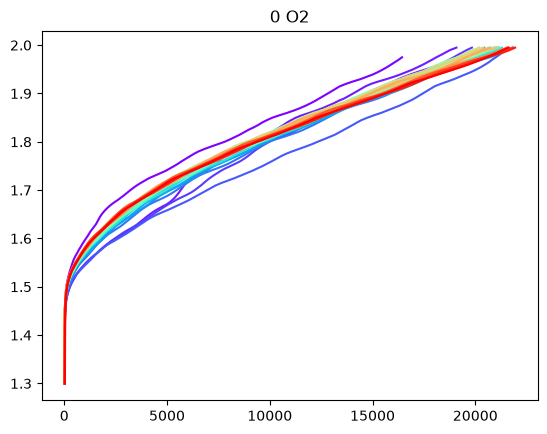

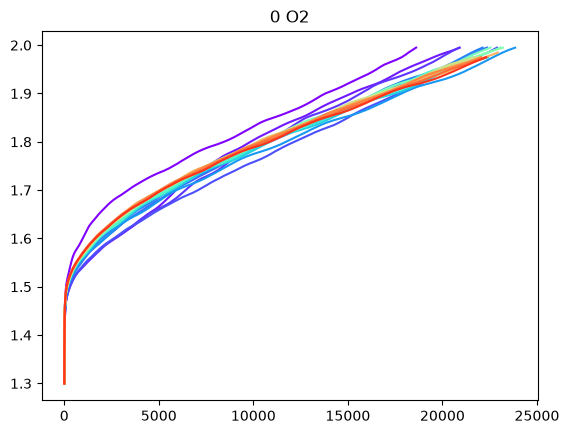

C:\Users\Herman\AppData\Local\Temp\ipykernel_22432\2710262304.py:21: UserWarning: loadtxt: input contained no data: "<_io.TextIOWrapper name='//ELECTROLYZER/PEM-WE_measurements/2025\\225_V_V IrOx series 0.1 sccm O2 15 sccm Ar\\V_Day4_procedure2_03_SV_C01.mpt' mode='r' encoding='latin1'>"
  data = np.loadtxt(f,skiprows = skip_rows)


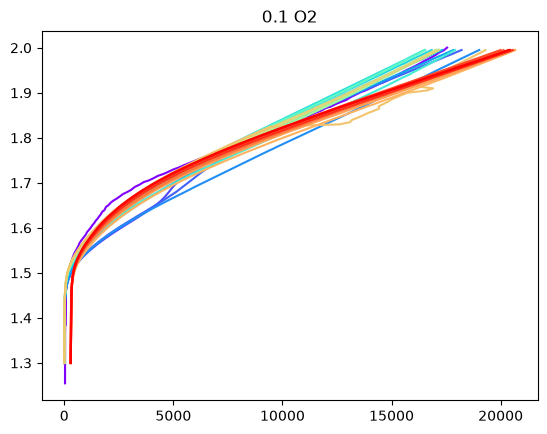

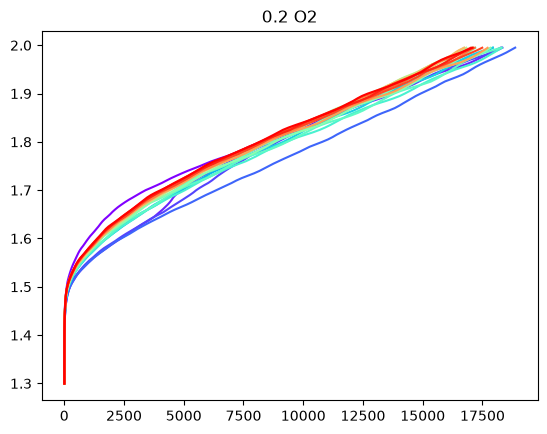

C:\Users\Herman\AppData\Local\Temp\ipykernel_22432\2710262304.py:21: UserWarning: loadtxt: input contained no data: "<_io.TextIOWrapper name='//ELECTROLYZER/PEM-WE_measurements/2025\\231_I_I IrOx series 0,5 sccm O2 14,5 sccm Ar\\I_Day2_procedure3_03_SV.mpt' mode='r' encoding='latin1'>"
  data = np.loadtxt(f,skiprows = skip_rows)


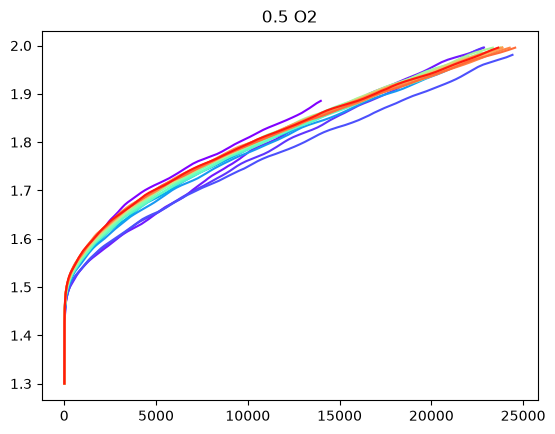

C:\Users\Herman\AppData\Local\Temp\ipykernel_22432\2710262304.py:21: UserWarning: loadtxt: input contained no data: "<_io.TextIOWrapper name='//ELECTROLYZER/PEM-WE_measurements/2025\\234_V_V IrOx series 1.0 sccm O2 14 sccm Ar\\V_Day7_procedure2_03_SV_C01.mpt' mode='r' encoding='latin1'>"
  data = np.loadtxt(f,skiprows = skip_rows)


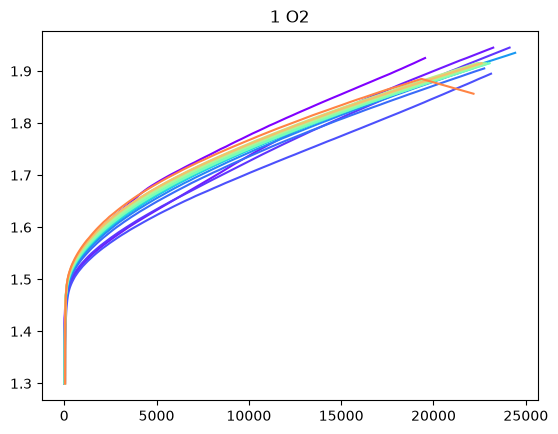

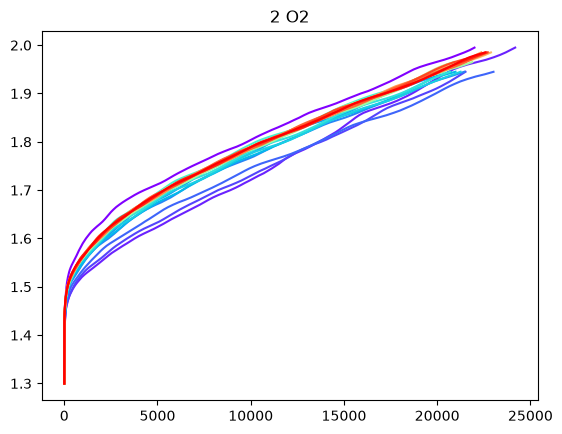

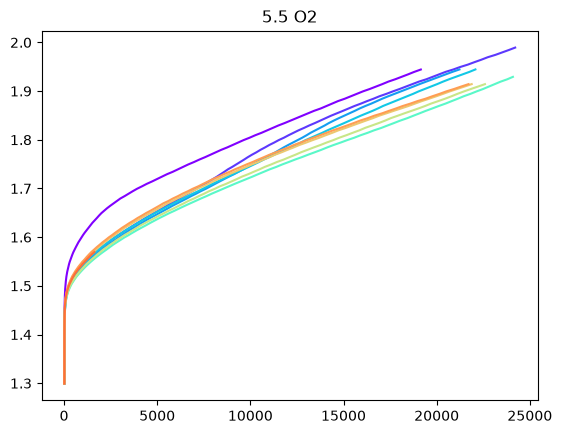

C:\Users\Herman\AppData\Local\Temp\ipykernel_22432\2710262304.py:21: UserWarning: loadtxt: input contained no data: "<_io.TextIOWrapper name='//ELECTROLYZER/PEM-WE_measurements/2025\\233_VII_VII IrOx series 5 sccm O2 10 sccm Ar\\VII_Day1_procedure2_03_SV_C01.mpt' mode='r' encoding='latin1'>"
  data = np.loadtxt(f,skiprows = skip_rows)


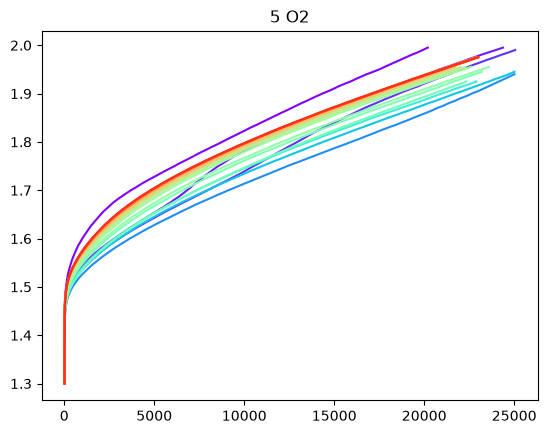

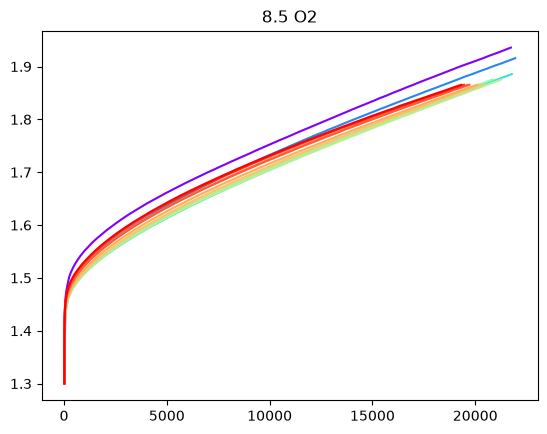

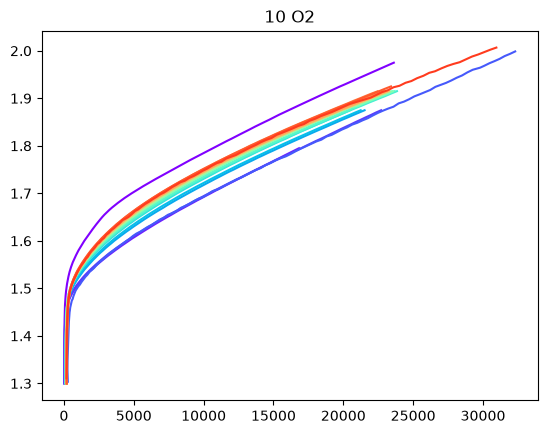

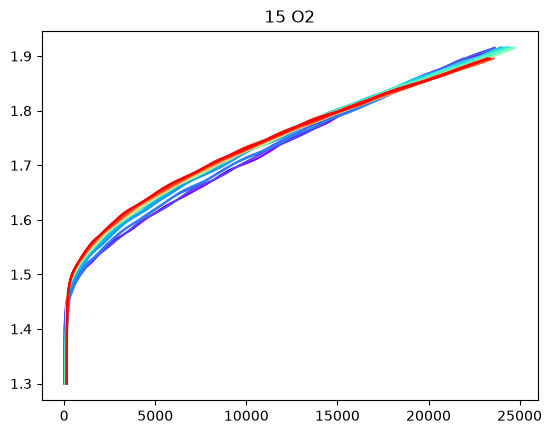

C:\Users\Herman\AppData\Local\Temp\ipykernel_22432\2710262304.py:21: UserWarning: loadtxt: input contained no data: "<_io.TextIOWrapper name='//ELECTROLYZER/PEM-WE_measurements/2025\\228_V_V IrOx series 20 sccm O2 0 sccm Ar\\IV_Day7_procedure2_03_SV_C01.mpt' mode='r' encoding='latin1'>"
  data = np.loadtxt(f,skiprows = skip_rows)


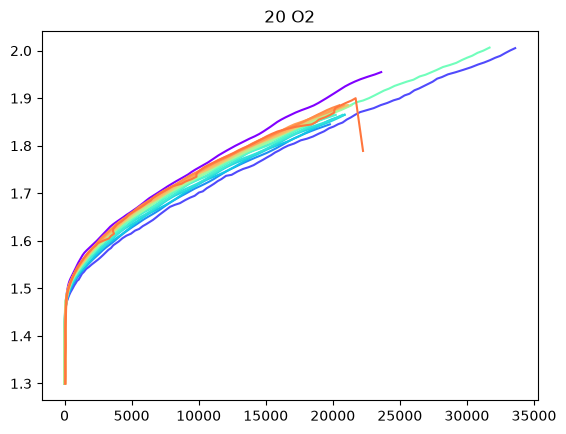

In [9]:
# labels = ["0,5 sccm","0,1 sccm","1 sccm","2 sccm","7 sccm","5 sccm"]
# 
voltage = [1.6,1.8,1.85,2.0]
for mea in MEA:
    mea['I'] = []
    mea['E'] = []
    
for j,mea in enumerate(MEA):
#     %matplotlib notebook  
    SV_number = 1
    maximum = 0
    for i,file in enumerate(mea['files']):
        
        cmap = plt.get_cmap('rainbow')
        colors = cmap(np.linspace(0,1,3*len(mea['files']))) 
        try:
            
                # print(file_SV)
            skip_rows = get_header_lines(file)
            with open(file, encoding='latin1') as f:
                data = np.loadtxt(f,skiprows = skip_rows)
            
            unique_vals = np.unique(data[:, 9])
            groups = [data[data[:,9] == val] for val in unique_vals]
            
            for k,group in enumerate(groups):

                mask = np.diff(group[:,6]) > 0   # True where next > previous
                mask = np.append(mask,False)
#                 print(mask)
#                 if mea == s231:
                plt.plot(group[:,8][mask],group[:,7][mask],'-',c = colors[3*i+k],markersize=1,label = 'Day: '+str(SV_number))
                SV_number += 1
                try:
#                     print(group[:,8][mask][0])
                    if any(mask):
                        mea['I'].append(group[:,8][mask])
                        mea['E'].append(group[:,7][mask])
                except:
                    pass
                    # print(np.list(group[:,8][mask]))
                
                # max_I = 0
                # for l,U in enumerate(voltage):

                # # Find index of closest element
                #     idx = np.argmin(np.abs(group[:,7][mask] - U))
                #     mea['I,U'][l].append(group[:,8][mask][idx])
 

        except:
            pass
    
    # print(mea['E'])
    # plt.legend()
    plt.title(mea['comp'])
    plt.show()


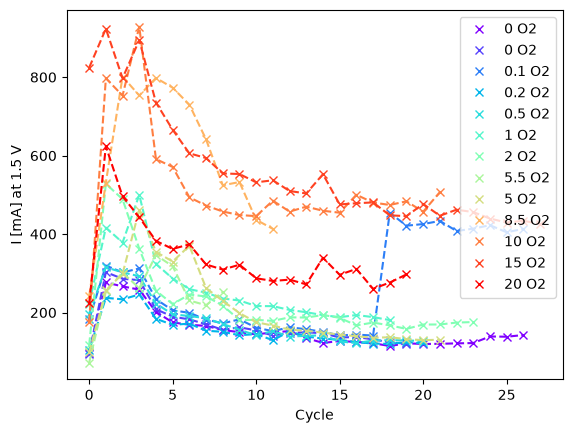

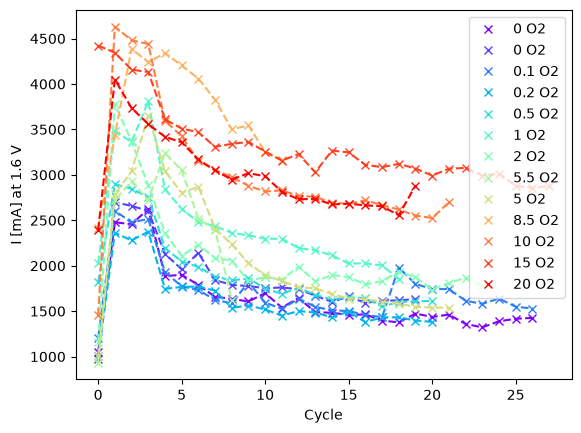

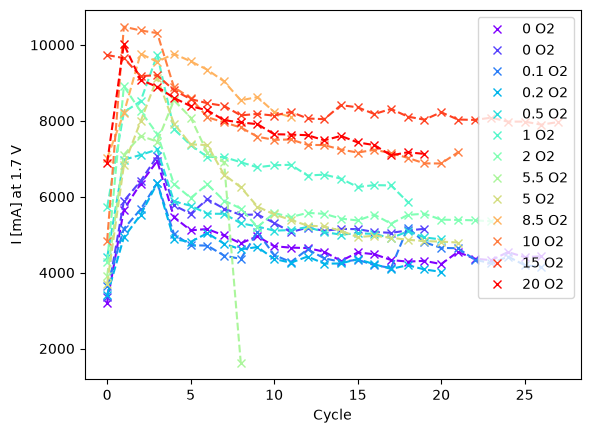

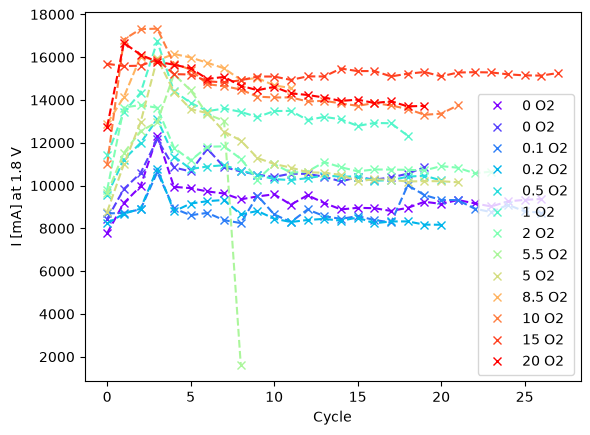

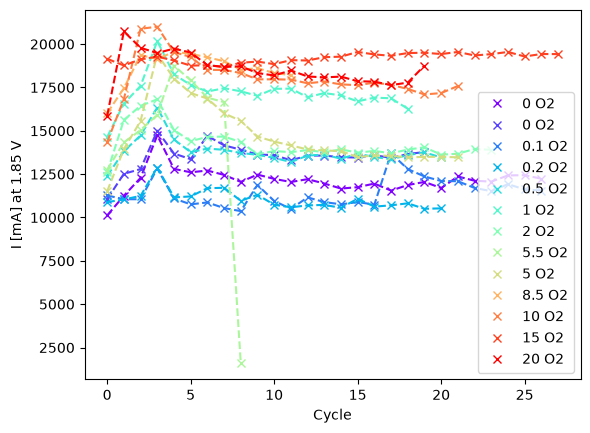

In [10]:
colors = cmap(np.linspace(0,1,len(MEA))) 
# %matplotlib notebook  
for U in [1.5,1.6,1.7,1.8,1.85]:
    for j,mea in enumerate(MEA):
        I_in_time = []
#         print(mea['I'])
        for cycle, I in enumerate(mea['I']):
#             print(I)
            idx = np.argmin(np.abs(mea['E'][cycle] - U))
            I_in_time.append(I[idx])
#             print(U,mea['name'],cycle,I[idx])
                # pass
    
#         plt.plot(I_in_time,'x',label = mea['comp'], c = colors[j])
#         plt.plot(I_in_time,'--', c = colors[j])
#         print(I_in_time)
#         plt.plot(np.array(I_in_time))
        plt.plot(I_in_time,'x',label = mea['comp'], c = colors[j])
        plt.plot(I_in_time,'--', c = colors[j])
    plt.xlabel('Cycle')
    plt.ylabel("I [mA] at "+str(U)+' V')
    plt.legend()
    # plt.title(str(U))
    plt.show()

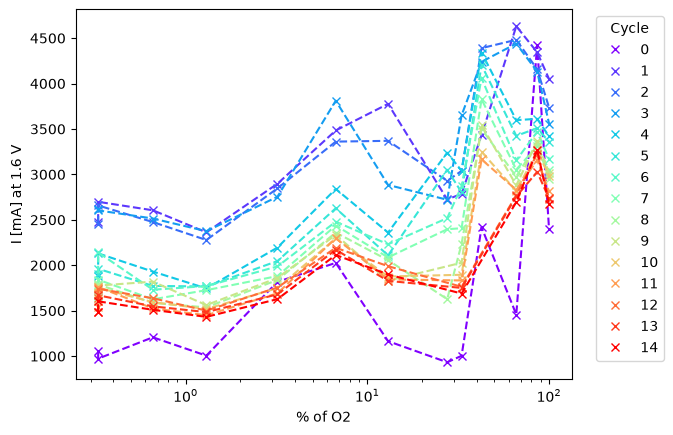

In [12]:
U = 1.6
labels = []

cycles = 15
colors = cmap(np.linspace(0,1,cycles)) 

for cycle in range(0,cycles):
    I_ox = []
    labels = []
    for mea in MEA:
        try:
            idx = np.argmin(np.abs(mea['E'][cycle] - U))
            I_ox.append(mea['I'][cycle][idx])
            labels.append(mea['%'])
        except:
            pass
                    # pass
    plt.plot(labels,I_ox,'x',c = colors[cycle],label = cycle)
    plt.plot(labels,I_ox,'--',c = colors[cycle])
plt.legend(title = 'Cycle',loc = 'upper right', bbox_to_anchor = (1.2,1))
plt.xscale('log')
plt.ylabel("I [mA] at "+str(U)+' V')
plt.xlabel('% of O2')
# plt.title(str(U))
plt.show()

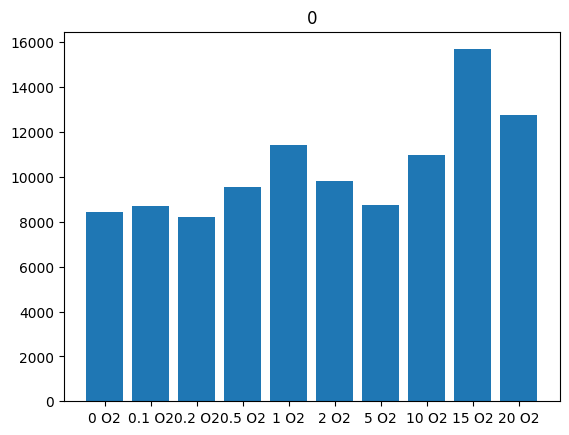

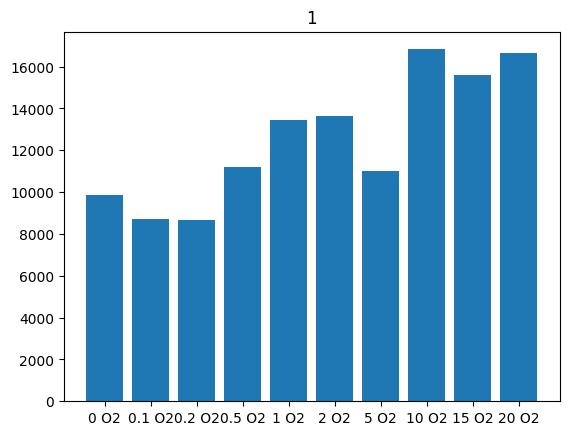

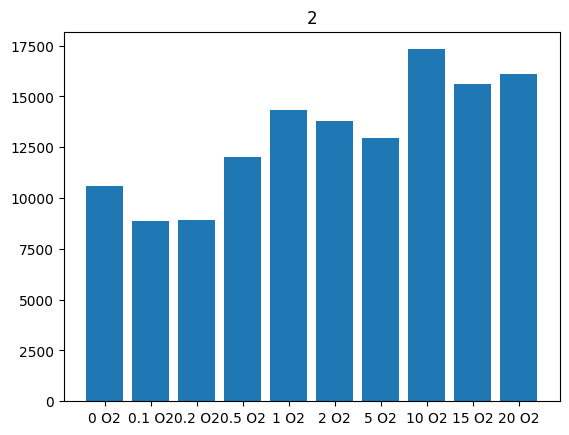

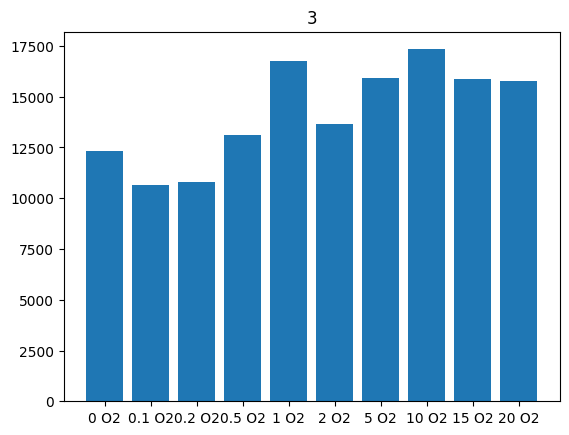

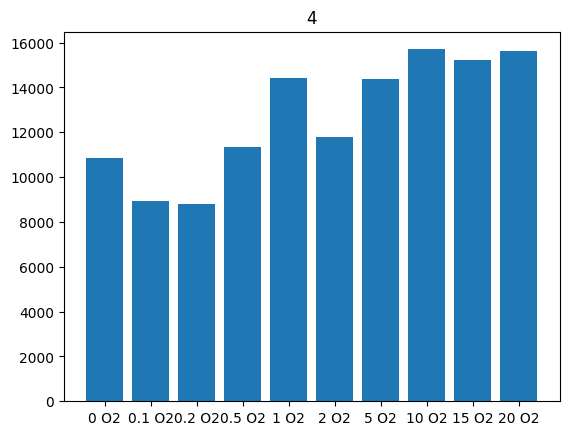

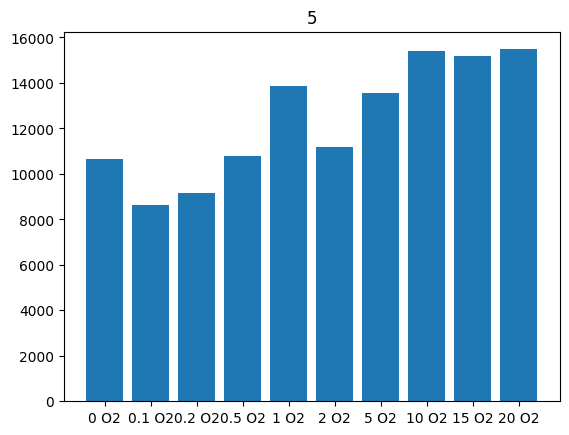

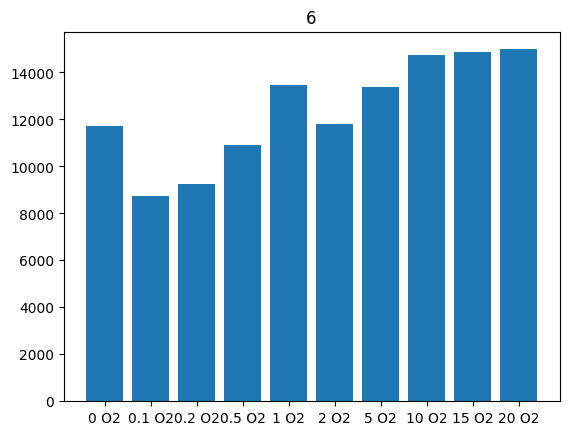

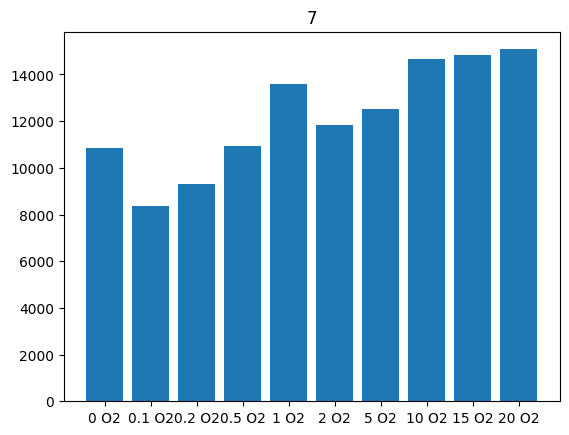

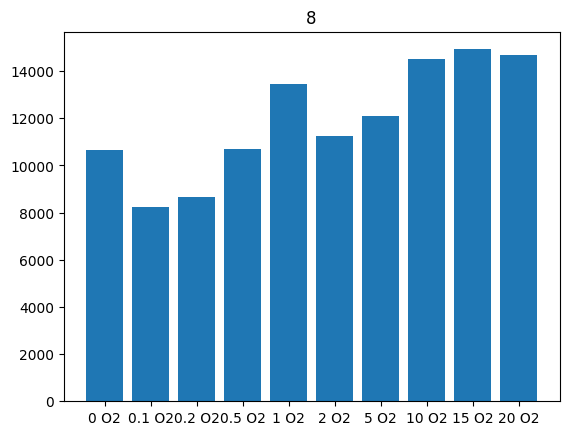

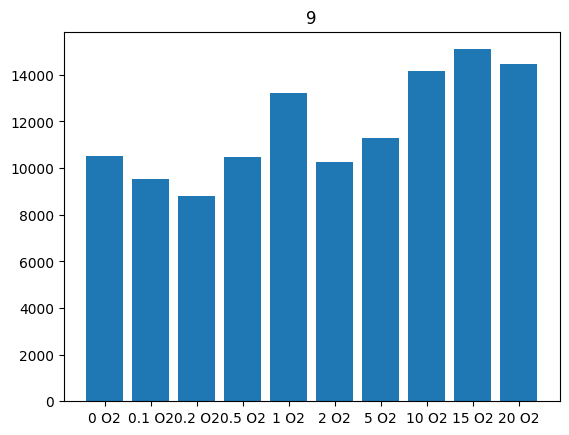

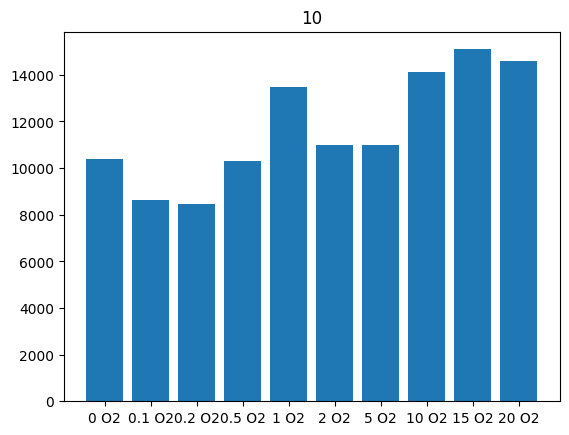

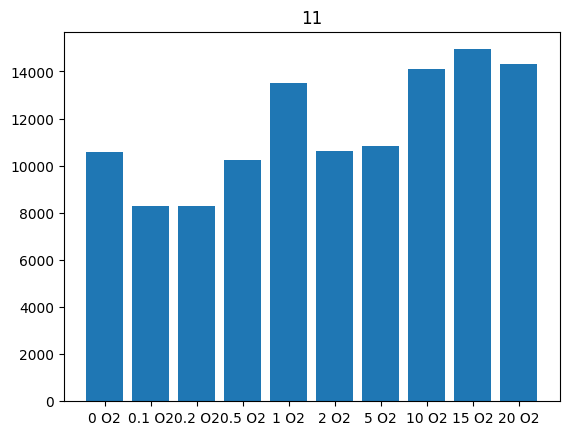

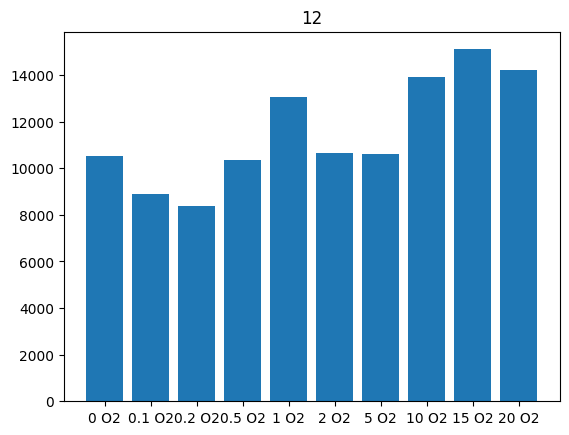

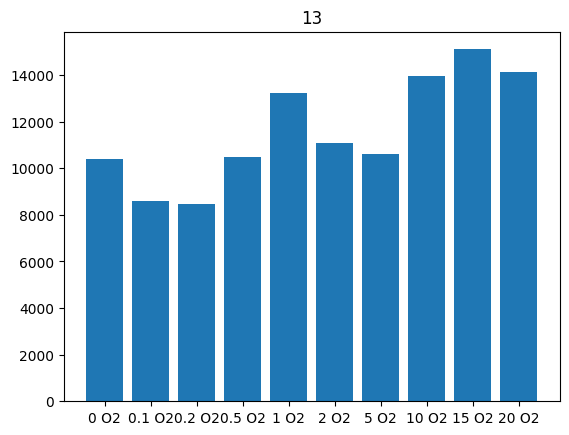

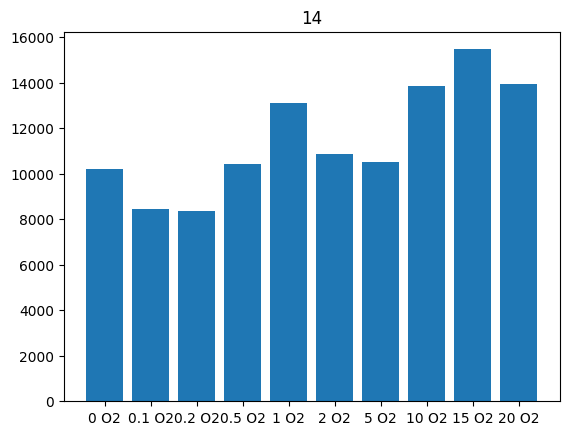

In [14]:
U = 1.8
labels = []

cycles = 15
colors = cmap(np.linspace(0,1,cycles)) 

for cycle in range(0,cycles):
    I_ox = []
    labels = []
    for mea in MEA:
        try:
            idx = np.argmin(np.abs(mea['E'][cycle] - U))
            I_ox.append(mea['I'][cycle][idx])
            labels.append(mea['comp'])
        except:
            pass
                    # pass
    plt.bar(labels,I_ox, width=0.8, bottom=None, align='center', data=None)
    # plt.plot(labels,I_ox,'--',c = colors[cycle])
# plt.legend(title = 'Cycle',loc = 'upper right', bbox_to_anchor = (1.2,1))
# plt.xscale('log')
# plt.ylabel("I [mA] at "+str(U)+' V')
# plt.xlabel('% of O2')
# plt.title(str(U))
    plt.title(cycle)
    plt.show()